# Task 3 – Analiza vânzărilor online de produse

**Curs:** Interactive Data Analysis and Visualization with Python  
**Modul:** Vizualizarea distribuției și corelației

## Obiectiv
Analizăm distribuția vânzărilor, comparăm categoriile și identificăm factorii asociați cu numărul de unități vândute. Notebook-ul urmărește cerințele din Task 3: histogramă, boxplot, comparație pe categorii, heatmap de corelații, scatter plot-uri și concluzii de business.

## 1. Importul bibliotecilor și încărcarea datelor

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Dacă rulezi notebook-ul în același folder cu CSV-ul, această cale este suficientă.
file_path = "Task_3-online_store_data.csv"
df = pd.read_csv(file_path)

print(f"Dimensiunea setului de date: {df.shape[0]} rânduri și {df.shape[1]} coloane")
df.head()

Dimensiunea setului de date: 2935 rânduri și 11 coloane


,product_name,category,price,quantity_in_stock,quantity_sold,brand,rating,num_of_ratings,date_added,color,revenue
0,"iPad mini (2021) (64GB, Blue)",Tablets,499.00,266.00,807.00,Apple,8.75,151.00,2/2/2022,blue,"402,693.00"
1,K55 RGB (Red),Keyboards,49.99,0.00,"1,117.00",Corsair,8.50,455.00,8/14/2022,red,"55,838.83"
2,Fenix 7 (Purple),Watches,699.99,0.00,530.00,Garmin,9.20,305.00,4/20/2022,purple,"370,994.70"
3,"Mate 40 (256GB, Orange)",Smartphones,899.00,182.00,"1,030.00",Huawei,8.50,500.00,10/23/2024,orange,"925,970.00"
4,Rival 600 (Red),Mice,79.99,35.00,"1,439.00",SteelSeries,9.25,556.00,9/29/2020,red,"115,105.61"


## 2. Explorarea setului de date

In [2]:
print("Informații despre coloane:")
df.info()

print("\nValori lipsă:")
display(df.isna().sum().to_frame("missing_values"))

print("\nStatistici descriptive:")
display(df.describe())

Informații despre coloane:
<class 'pandas.DataFrame'>
RangeIndex: 2935 entries, 0 to 2934
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   product_name       2935 non-null   str    
 1   category           2935 non-null   str    
 2   price              2935 non-null   float64
 3   quantity_in_stock  2894 non-null   float64
 4   quantity_sold      2935 non-null   float64
 5   brand              2935 non-null   str    
 6   rating             2935 non-null   float64
 7   num_of_ratings     2935 non-null   float64
 8   date_added         2935 non-null   str    
 9   color              2935 non-null   str    
 10  revenue            2935 non-null   float64
dtypes: float64(6), str(5)
memory usage: 252.4 KB

Valori lipsă:


,missing_values
product_name,0
category,0
price,0
quantity_in_stock,41
quantity_sold,0
brand,0
rating,0
num_of_ratings,0
date_added,0
color,0



Statistici descriptive:


,price,quantity_in_stock,quantity_sold,rating,num_of_ratings,revenue
count,"2,935.00","2,894.00","2,935.00","2,935.00","2,935.00","2,935.00"
mean,417.94,163.61,"1,041.23",8.60,404.00,"390,283.65"
std,570.07,166.61,339.84,0.39,235.85,"484,255.11"
min,6.00,0.00,0.00,5.50,0.00,0.00
25%,90.00,0.00,793.00,8.50,203.00,"90,571.75"
50%,199.00,119.00,"1,031.00",8.70,406.00,"192,500.00"
75%,499.00,310.75,"1,272.00",8.75,603.00,"497,671.17"
max,"8,195.00",500.00,"3,596.00",9.75,"2,908.00","3,868,040.00"


### Observație
Setul de date conține informații despre produse, categorii, preț, stoc, unități vândute, rating, numărul de evaluări și venit. Înainte de vizualizare verificăm valorile lipsă și distribuțiile numerice.

## 3. Distribuția numărului de unități vândute

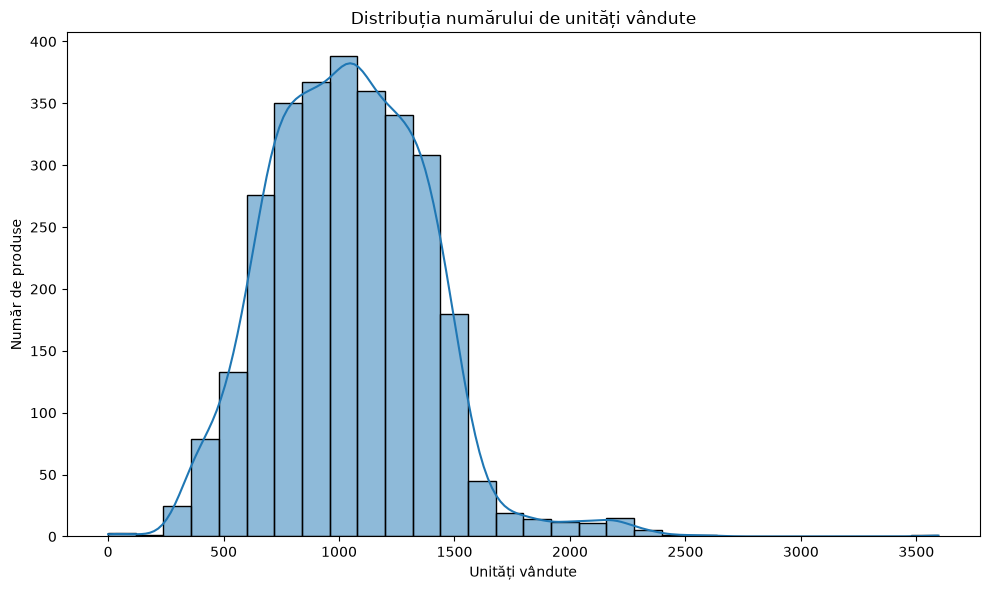

In [3]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="quantity_sold", bins=30, kde=True)
plt.title("Distribuția numărului de unități vândute")
plt.xlabel("Unități vândute")
plt.ylabel("Număr de produse")
plt.tight_layout()
plt.show()

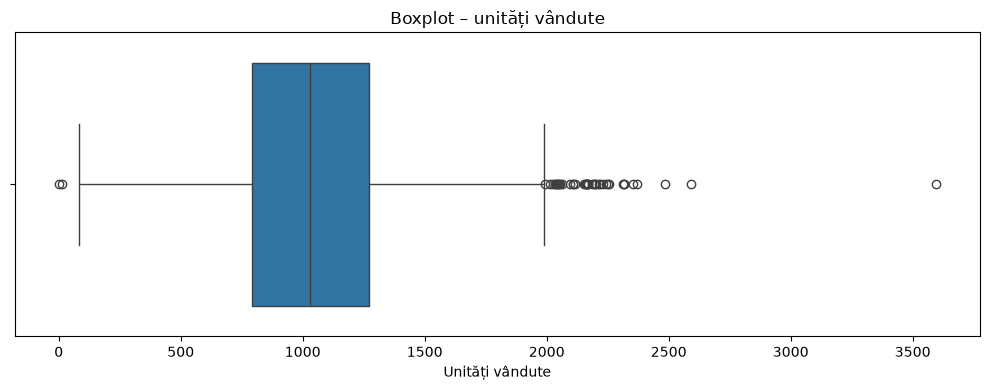

Top 10 produse după numărul de unități vândute:


,product_name,category,quantity_sold,price,rating,revenue
2307,"iPhone 12 (256GB, Silver)",Smartphones,"3,596.00",749.00,8.75,"2,693,404.00"
381,Switch (Gray),Gaming Consoles,"2,592.00",299.99,9.25,"777,574.08"
1496,NES (White),Gaming Consoles,"2,483.00",150.00,9.50,"372,450.00"
1119,PlayStation 5 (Red),Gaming Consoles,"2,371.00",499.99,9.50,"1,185,476.29"
209,Xbox Series X (White),Gaming Consoles,"2,352.00",499.99,8.75,"1,175,976.48"
2392,N64 (Purple),Gaming Consoles,"2,317.00",120.00,9.00,"278,040.00"
1575,Wii (White),Gaming Consoles,"2,315.00",89.99,8.75,"208,326.85"
2438,PlayStation 1 (White),Gaming Consoles,"2,314.00",120.00,8.50,"277,680.00"
2857,Genesis Mini (Brown),Gaming Consoles,"2,256.00",79.99,8.75,"180,457.44"
804,PS TV (Blue),Gaming Consoles,"2,251.00",99.99,8.50,"225,077.49"


In [4]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="quantity_sold")
plt.title("Boxplot – unități vândute")
plt.xlabel("Unități vândute")
plt.tight_layout()
plt.show()

print("Top 10 produse după numărul de unități vândute:")
display(
    df.nlargest(10, "quantity_sold")[
        ["product_name", "category", "quantity_sold", "price", "rating", "revenue"]
    ]
)

### Interpretare
Histograma arată forma distribuției vânzărilor, iar boxplot-ul evidențiază valorile extreme. Produsele din partea superioară a distribuției trebuie urmărite separat deoarece pot avea o contribuție disproporționat de mare la vânzări.

## 4. Compararea vânzărilor între categorii

,count,sum,mean,median
category,,,,
Gaming Consoles,193,"296,586.00","1,536.72","1,525.00"
Clothing,228,"246,764.00","1,082.30","1,068.50"
Shoes,218,"244,191.00","1,120.14","1,117.50"
Headphones,207,"234,005.00","1,130.46","1,146.00"
Smartphones,233,"226,808.00",973.42,934.00
Kitchen,196,"223,940.00","1,142.55","1,121.50"
Toys,198,"223,729.00","1,129.94","1,148.50"
Mice,197,"223,107.00","1,132.52","1,106.00"
Tablets,225,"214,154.00",951.80,947.00


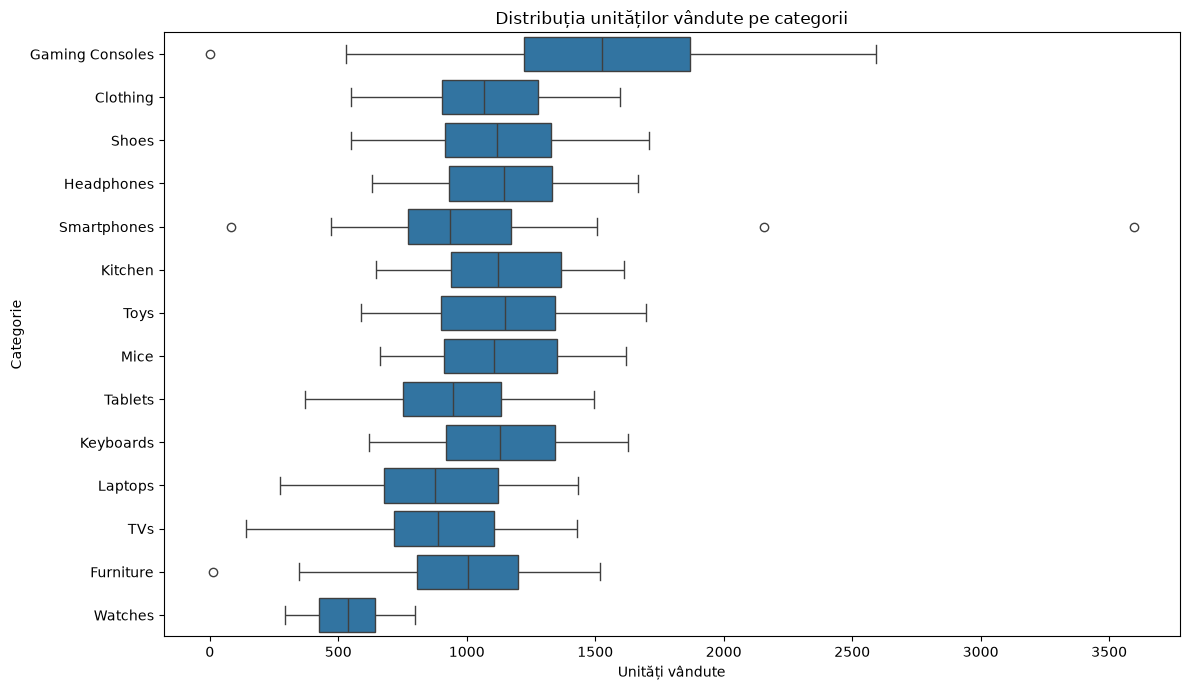

In [5]:
category_stats = (
    df.groupby("category")["quantity_sold"]
      .agg(["count", "sum", "mean", "median"])
      .sort_values("sum", ascending=False)
)

display(category_stats)

plt.figure(figsize=(12, 7))
order = category_stats.index
sns.boxplot(data=df, x="quantity_sold", y="category", order=order)
plt.title("Distribuția unităților vândute pe categorii")
plt.xlabel("Unități vândute")
plt.ylabel("Categorie")
plt.tight_layout()
plt.show()

### Interpretare
Boxplot-ul permite compararea rapidă a distribuțiilor între categorii. Pentru decizii comerciale este util să privim atât totalul vândut, cât și nivelul tipic al unui produs din categorie (mediană/medie), deoarece o categorie poate avea multe produse fără ca fiecare produs să fie performant.

## 5. Analiza corelațiilor

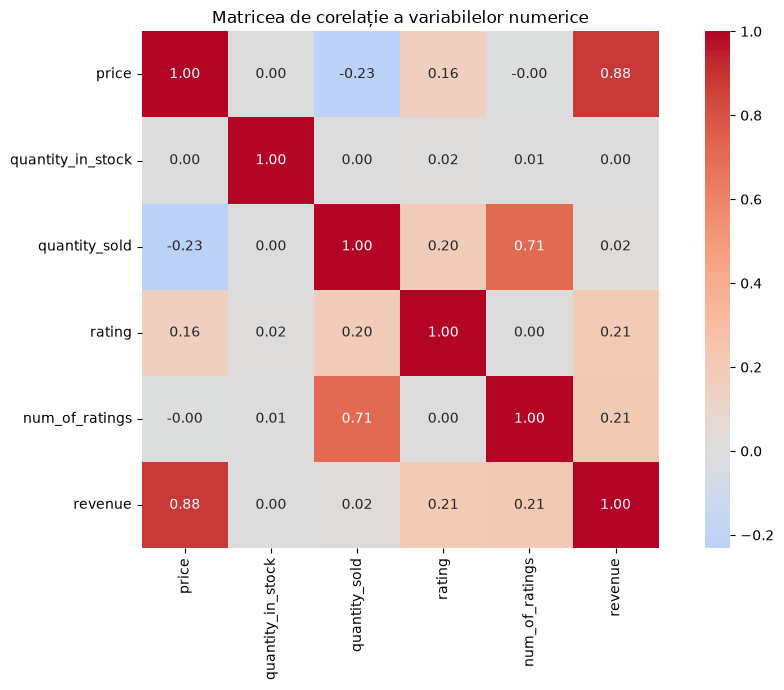

,price,quantity_in_stock,quantity_sold,rating,num_of_ratings,revenue
price,1.00,0.00,-0.23,0.16,-0.00,0.88
quantity_in_stock,0.00,1.00,0.00,0.02,0.01,0.00
quantity_sold,-0.23,0.00,1.00,0.20,0.71,0.02
rating,0.16,0.02,0.20,1.00,0.00,0.21
num_of_ratings,-0.00,0.01,0.71,0.00,1.00,0.21
revenue,0.88,0.00,0.02,0.21,0.21,1.00


In [6]:
numeric_cols = [
    "price",
    "quantity_in_stock",
    "quantity_sold",
    "rating",
    "num_of_ratings",
    "revenue"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matricea de corelație a variabilelor numerice")
plt.tight_layout()
plt.show()

display(corr.round(3))

### Interpretare
Corelația măsoară asocierea liniară dintre două variabile și nu dovedește cauzalitatea. În acest set de date, relația dintre **quantity_sold** și **rating** este puternică pozitivă, iar relația dintre **quantity_sold** și **price** este negativă. Relația dintre **revenue** și **price** este foarte puternică, ceea ce este de așteptat deoarece venitul este legat direct de preț și de cantitatea vândută.

Prin urmare, corelațiile trebuie interpretate împreună cu graficele și cu contextul de business.

## 6. Analiza factorilor cheie ai succesului

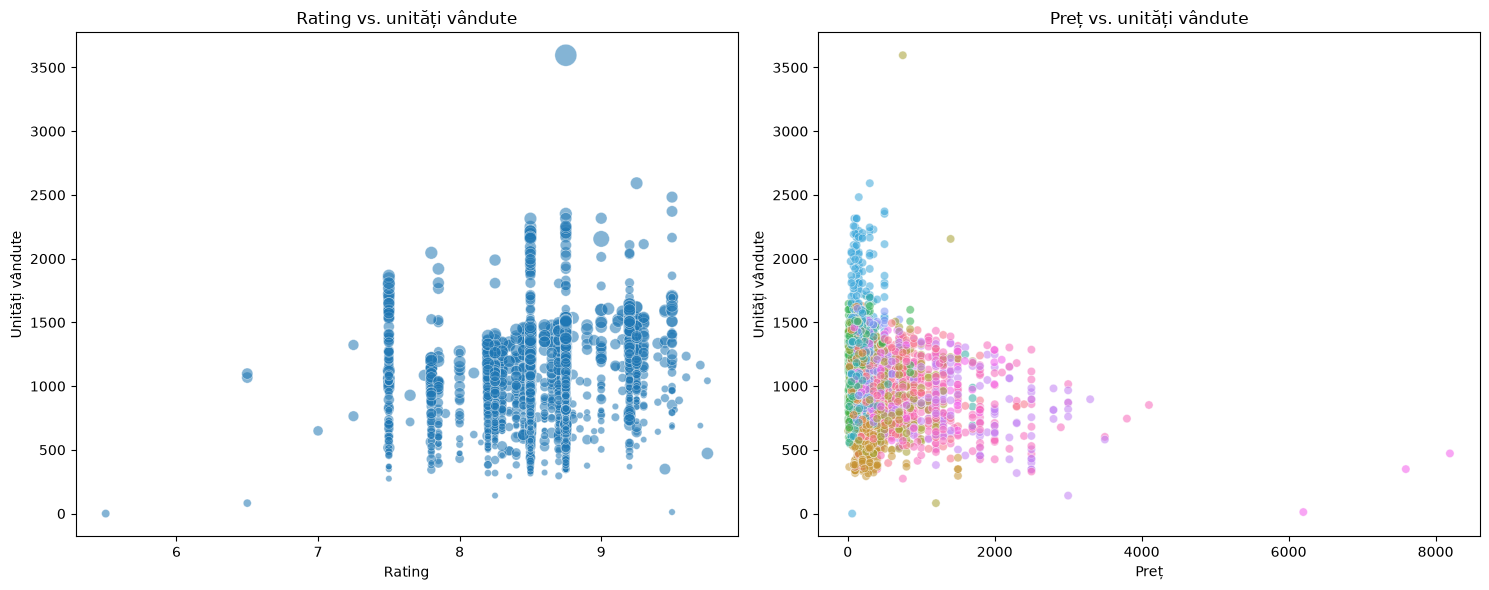

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=df, x="rating", y="quantity_sold",
    size="num_of_ratings", sizes=(20, 250), alpha=0.55, ax=axes[0],
    legend=False
)
axes[0].set_title("Rating vs. unități vândute")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Unități vândute")

sns.scatterplot(
    data=df, x="price", y="quantity_sold",
    hue="category", alpha=0.55, ax=axes[1],
    legend=False
)
axes[1].set_title("Preț vs. unități vândute")
axes[1].set_xlabel("Preț")
axes[1].set_ylabel("Unități vândute")

plt.tight_layout()
plt.show()

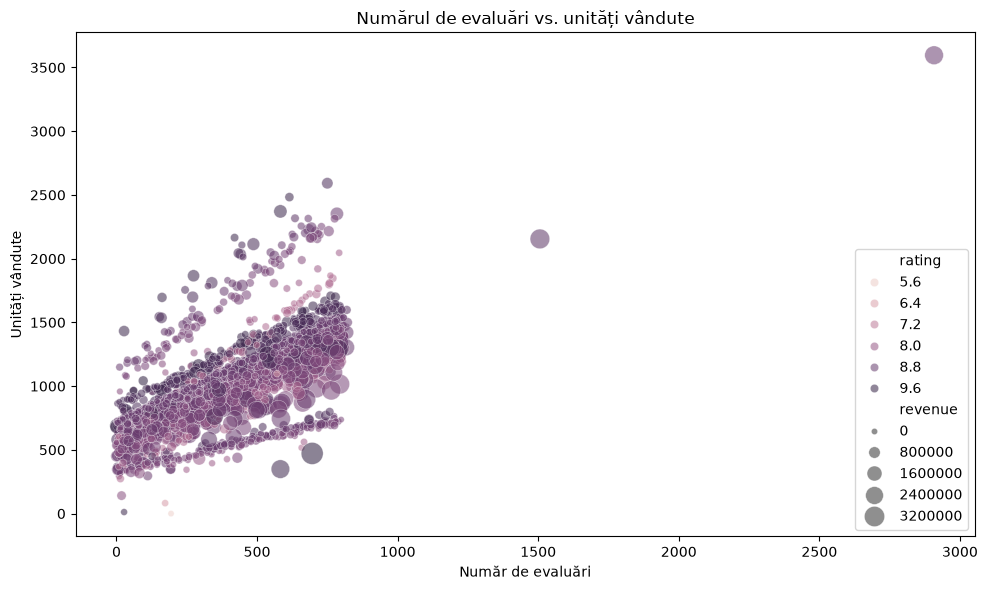

In [8]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, x="num_of_ratings", y="quantity_sold",
    hue="rating", size="revenue", sizes=(20, 250), alpha=0.55
)
plt.title("Numărul de evaluări vs. unități vândute")
plt.xlabel("Număr de evaluări")
plt.ylabel("Unități vândute")
plt.tight_layout()
plt.show()

### Interpretare
Scatter plot-urile permit verificarea vizuală a relațiilor identificate în heatmap. Un rating mai mare este asociat în acest set de date cu un număr mai mare de unități vândute. Prețul are o asociere negativă cu unitățile vândute, ceea ce sugerează că produsele mai scumpe tind să vândă mai puține unități. Aceste rezultate sunt asocieri statistice și nu demonstrează singure că un factor cauzează vânzările.

## 7. Produsele și categoriile cu performanță ridicată

In [9]:
print("Top 10 produse după unități vândute:")
display(
    df.nlargest(10, "quantity_sold")[
        ["product_name", "category", "quantity_sold", "price", "rating", "revenue"]
    ].reset_index(drop=True)
)

print("Categorii ordonate după totalul unităților vândute:")
display(category_stats.sort_values("sum", ascending=False))

Top 10 produse după unități vândute:


,product_name,category,quantity_sold,price,rating,revenue
0,"iPhone 12 (256GB, Silver)",Smartphones,"3,596.00",749.00,8.75,"2,693,404.00"
1,Switch (Gray),Gaming Consoles,"2,592.00",299.99,9.25,"777,574.08"
2,NES (White),Gaming Consoles,"2,483.00",150.00,9.50,"372,450.00"
3,PlayStation 5 (Red),Gaming Consoles,"2,371.00",499.99,9.50,"1,185,476.29"
4,Xbox Series X (White),Gaming Consoles,"2,352.00",499.99,8.75,"1,175,976.48"
5,N64 (Purple),Gaming Consoles,"2,317.00",120.00,9.00,"278,040.00"
6,Wii (White),Gaming Consoles,"2,315.00",89.99,8.75,"208,326.85"
7,PlayStation 1 (White),Gaming Consoles,"2,314.00",120.00,8.50,"277,680.00"
8,Genesis Mini (Brown),Gaming Consoles,"2,256.00",79.99,8.75,"180,457.44"
9,PS TV (Blue),Gaming Consoles,"2,251.00",99.99,8.50,"225,077.49"


Categorii ordonate după totalul unităților vândute:


,count,sum,mean,median
category,,,,
Gaming Consoles,193,"296,586.00","1,536.72","1,525.00"
Clothing,228,"246,764.00","1,082.30","1,068.50"
Shoes,218,"244,191.00","1,120.14","1,117.50"
Headphones,207,"234,005.00","1,130.46","1,146.00"
Smartphones,233,"226,808.00",973.42,934.00
Kitchen,196,"223,940.00","1,142.55","1,121.50"
Toys,198,"223,729.00","1,129.94","1,148.50"
Mice,197,"223,107.00","1,132.52","1,106.00"
Tablets,225,"214,154.00",951.80,947.00


## 8. Concluzii de business

- **Gaming Consoles** are cel mai mare total de unități vândute dintre categorii în acest set de date.
- **iPhone 12 (256GB, Silver)** este produsul cu cel mai mare număr de unități vândute dintre produsele analizate.
- **Rating-ul** are o asociere pozitivă puternică cu unitățile vândute, astfel încât produsele bine evaluate apar frecvent în zona de vânzări ridicate.
- **Prețul** are o asociere negativă cu unitățile vândute: produsele mai scumpe tind să aibă volume mai mici.
- **Stocul disponibil** are o corelație aproape nulă cu unitățile vândute în datele analizate, deci nu apare ca un predictor liniar important al volumului de vânzări.
- **Venitul** este foarte strâns legat de preț și de cantitatea vândută; trebuie interpretat ca rezultat comercial, nu ca factor independent al vânzărilor.

### Recomandare
Pentru decizii comerciale, merită acordată atenție produselor cu rating bun și volum mare de vânzări, iar produsele cu preț ridicat și volum redus pot necesita strategii diferite de preț, promovare sau poziționare. Corelațiile prezentate trebuie tratate ca asocieri, nu ca dovezi de cauzalitate.

## 9. Verificare finală

Notebook-ul include elementele cerute în Task 3:
- explorarea setului de date;
- histogramă pentru distribuția vânzărilor;
- boxplot pentru valori extreme;
- comparație între categorii;
- heatmap pentru corelații;
- scatter plot-uri pentru factorii cheie;
- interpretări și concluzii de business.

**Fișierul CSV trebuie să fie în același folder cu notebook-ul atunci când este rulat în Jupyter Notebook.**